# Huấn luyện Plant Disease AI — MobileNetV2 (15 lớp)

Notebook chính thức của dự án. Tự động tải PlantVillage bằng TensorFlow Datasets, lọc đúng 15 lớp, tạo tập train/validation/test phân tầng, huấn luyện MobileNetV2 pretrained ImageNet và đánh giá trên tập test độc lập.

**Không cần upload dataset thủ công.** Lần đầu chạy cần Internet, dung lượng lưu trữ và thời gian tải dữ liệu. Model hiện tại trong repository không bị ghi đè.

In [5]:
# 1. Cài thư viện và kết nối Google Drive
!pip -q install --upgrade tensorflow-datasets importlib-resources scikit-learn matplotlib tqdm
from google.colab import drive
drive.mount('/content/drive')
import os, sys, subprocess, json, shutil, re
from pathlib import Path
import tensorflow as tf
import tensorflow_datasets as tfds
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "Không có GPU — huấn luyện sẽ chậm")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# 2. Lấy mã nguồn chính thức từ main
REPO_DIR = "/content/Plant-Disease-Detection"
REPO_URL = "https://github.com/ShimeKano/Plant-Disease-Detection.git"
if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", "--branch", "main", REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", "-C", REPO_DIR, "fetch", "origin", "main"], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "checkout", "main"], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "reset", "--hard", "origin/main"], check=True)
print("Source:", REPO_DIR)
print("Training script:", Path(REPO_DIR) / "src/train.py")

In [7]:
# 3. Tải PlantVillage tự động và lọc đúng 15 lớp
# Dùng cache riêng trong /content để tránh thư mục TFDS cũ bị tải dở.
# importlib_resources được cài ở cell 1 để tương thích môi trường Python 3.13.
TFDS_DATA_DIR = "/content/tfds_cache"
Path(TFDS_DATA_DIR).mkdir(parents=True, exist_ok=True)
EXPECTED = [
 "Pepper__bell___Bacterial_spot","Pepper__bell___healthy",
 "Potato___Early_blight","Potato___Late_blight","Potato___healthy",
 "Tomato__Bacterial_spot","Tomato__Early_blight","Tomato__Late_blight",
 "Tomato__Leaf_Mold","Tomato__Septoria_leaf_spot",
 "Tomato__Spider_mites_Two_spotted_spider_mite","Tomato__Target_Spot",
 "Tomato__Tomato_YellowLeaf__Curl_Virus","Tomato__Tomato_mosaic_virus","Tomato__healthy"
]
def norm_label(s): return re.sub(r"[^a-z0-9]", "", s.lower())
# Tên nhãn TFDS có dấu phẩy/underscore khác tên thư mục trong app;
# chuẩn hóa để đối chiếu mà không phụ thuộc số lượng dấu gạch dưới.
builder = tfds.builder("plant_village", data_dir=TFDS_DATA_DIR)
label_names = builder.info.features["label"].names
lookup = {norm_label(n): n for n in label_names}
label_to_folder = {}
for folder in EXPECTED:
    key = norm_label(folder)
    if key not in lookup:
        raise ValueError(f"Không tìm thấy lớp {folder} trong TFDS. Nhãn có sẵn: {label_names}")
    label_to_folder[lookup[key]] = folder
print("15 lớp được chọn:", len(label_to_folder))
print("Đang tải PlantVillage (lần đầu có thể mất vài phút)...")
# Tải và chuẩn bị dataset trong cache sạch riêng.
# Nếu lần trước tải lỗi, xóa đúng cache riêng này rồi chạy lại cell.
builder.download_and_prepare()
info = builder.info
ds = builder.as_dataset(split="train", as_supervised=True, shuffle_files=False)
DATASET_DIR = Path("/content/plantvillage_15")
if DATASET_DIR.exists(): shutil.rmtree(DATASET_DIR)
for folder in EXPECTED: (DATASET_DIR/folder).mkdir(parents=True, exist_ok=True)
counts = {name: 0 for name in EXPECTED}
from tqdm.auto import tqdm
for image, label in tqdm(tfds.as_numpy(ds), total=info.splits["train"].num_examples, desc="Lọc ảnh PlantVillage"):
    original = info.features["label"].int2str(int(label))
    folder = label_to_folder.get(original)
    if folder is None: continue
    out = DATASET_DIR/folder/f"{counts[folder]:06d}.jpg"
    tf.io.write_file(str(out), tf.io.encode_jpeg(image, quality=95))
    counts[folder] += 1
print("Hoàn tất tải/lọc dữ liệu:")
for k,v in counts.items(): print(k, v)
missing = [k for k,v in counts.items() if v < 3]
if missing: raise RuntimeError(f"Lớp thiếu ảnh hoặc không khớp nhãn TFDS: {missing}")
print("Tổng ảnh:", sum(counts.values()))

15 lớp được chọn: 15
Đang tải PlantVillage (lần đầu có thể mất vài phút)...


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /content/tfds_cache/plant_village/incomplete.C7YUW7_1.0.2/plant_village-train.tfrecord-[0-9][0-9][0-…

Dataset plant_village downloaded and prepared to /content/tfds_cache/plant_village/1.0.2. Subsequent calls will reuse this data.


Lọc ảnh PlantVillage:   0%|          | 0/54303 [00:00<?, ?it/s]

Hoàn tất tải/lọc dữ liệu:
Pepper__bell___Bacterial_spot 997
Pepper__bell___healthy 1477
Potato___Early_blight 1000
Potato___Late_blight 1000
Potato___healthy 152
Tomato__Bacterial_spot 2127
Tomato__Early_blight 1000
Tomato__Late_blight 1908
Tomato__Leaf_Mold 952
Tomato__Septoria_leaf_spot 1771
Tomato__Spider_mites_Two_spotted_spider_mite 1676
Tomato__Target_Spot 1404
Tomato__Tomato_YellowLeaf__Curl_Virus 5357
Tomato__Tomato_mosaic_virus 373
Tomato__healthy 1591
Tổng ảnh: 22785


In [8]:
# 4. Cấu hình huấn luyện và sao lưu
OUTPUT_DIR = "/content/plant_disease_training_output"
DRIVE_BACKUP_DIR = "/content/drive/MyDrive/PlantDiseaseTraining/checkpoints"
IMG_SIZE = 128
BATCH_SIZE = 32
HEAD_EPOCHS = 12
FINE_TUNE_EPOCHS = 8
SEED = 42

Path(DRIVE_BACKUP_DIR).mkdir(parents=True, exist_ok=True)
print("Dataset:", DATASET_DIR, "| Output:", OUTPUT_DIR)
print("Checkpoint Drive:", DRIVE_BACKUP_DIR)
print("Mỗi epoch sẽ sao lưu latest_checkpoint.keras và best_model.keras lên Drive.")


Dataset: /content/plantvillage_15 | Output: /content/plant_disease_training_output
Checkpoint Drive: /content/drive/MyDrive/PlantDiseaseTraining/checkpoints
Mỗi epoch sẽ sao lưu latest_checkpoint.keras và best_model.keras lên Drive.


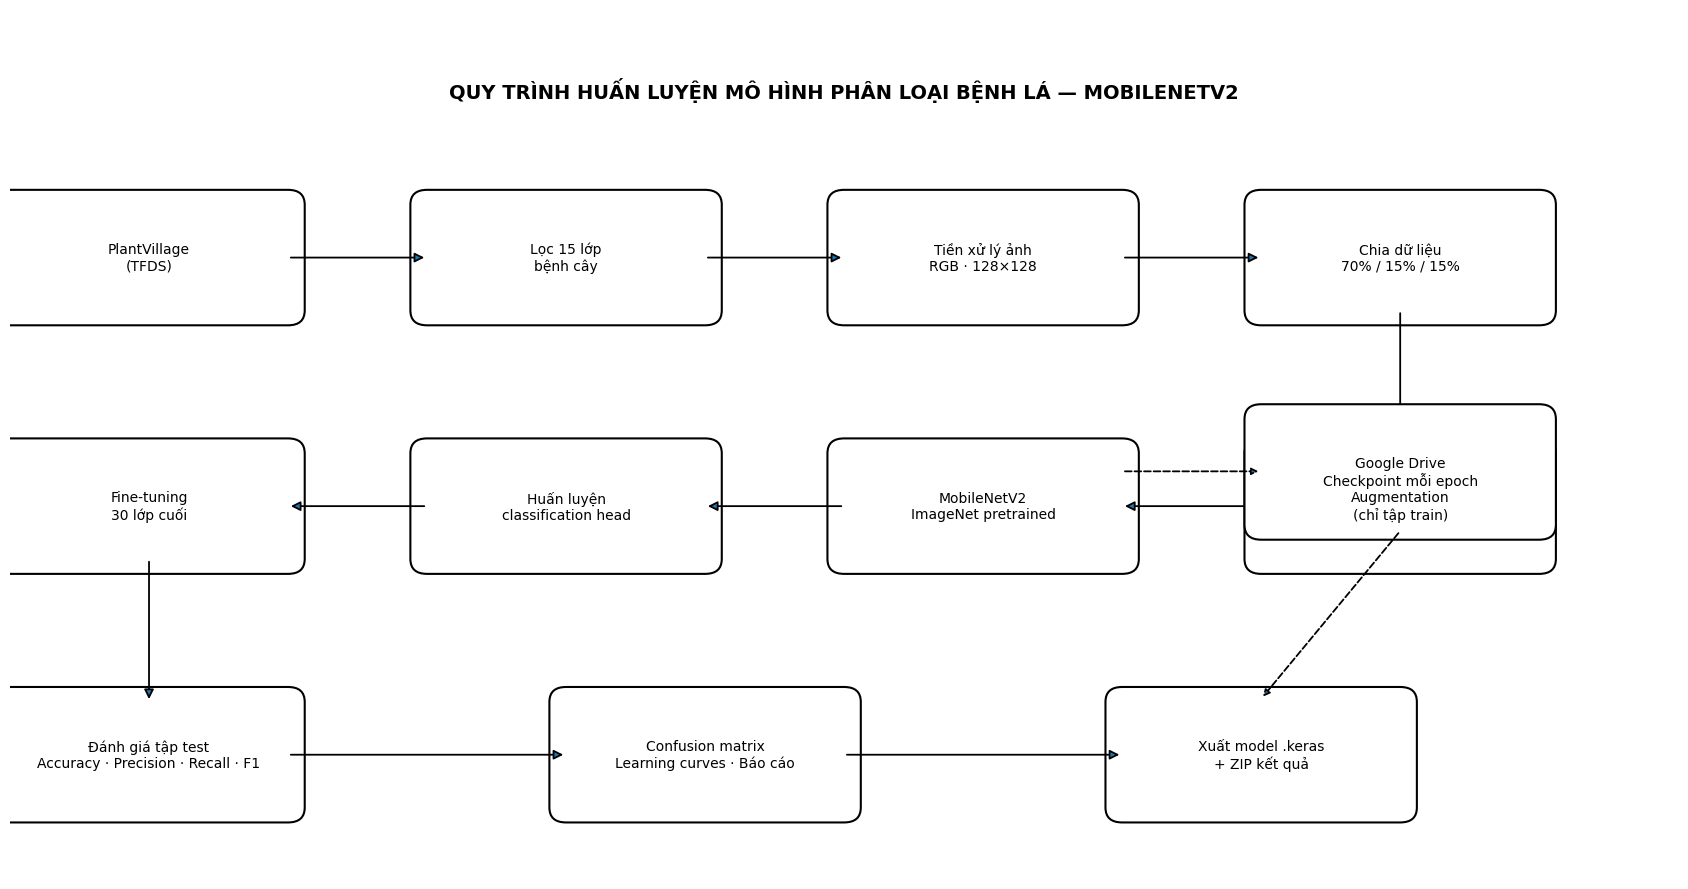

Đã lưu sơ đồ: /content/plant_disease_training_output/workflow_diagram.png
Bản trên Drive: /content/drive/MyDrive/PlantDiseaseTraining/workflow_diagram.png


In [9]:
# 5. Vẽ sơ đồ quy trình huấn luyện để đưa vào báo cáo
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from pathlib import Path

fig, ax = plt.subplots(figsize=(17, 9))
ax.set_xlim(-1, 11)
ax.set_ylim(-3, 4)
ax.axis("off")

nodes = {
    "data": (0, 2, "PlantVillage\n(TFDS)"),
    "filter": (3, 2, "Lọc 15 lớp\nbệnh cây"),
    "prep": (6, 2, "Tiền xử lý ảnh\nRGB · 128×128"),
    "split": (9, 2, "Chia dữ liệu\n70% / 15% / 15%"),
    "aug": (9, 0, "Augmentation\n(chỉ tập train)"),
    "model": (6, 0, "MobileNetV2\nImageNet pretrained"),
    "head": (3, 0, "Huấn luyện\nclassification head"),
    "tune": (0, 0, "Fine-tuning\n30 lớp cuối"),
    "eval": (0, -2, "Đánh giá tập test\nAccuracy · Precision · Recall · F1"),
    "report": (4, -2, "Confusion matrix\nLearning curves · Báo cáo"),
    "export": (8, -2, "Xuất model .keras\n+ ZIP kết quả")
}
box_w, box_h = 2.0, 0.85
for key, (x, y, label) in nodes.items():
    patch = FancyBboxPatch((x-box_w/2, y-box_h/2), box_w, box_h,
                           boxstyle="round,pad=0.12", linewidth=1.5,
                           edgecolor="black", facecolor="white")
    ax.add_patch(patch)
    ax.text(x, y, label, ha="center", va="center", fontsize=10)

def arrow(a, b, style="-", rad=0.0):
    x1,y1,_=nodes[a]; x2,y2,_=nodes[b]
    dx,dy=x2-x1,y2-y1
    length=(dx*dx+dy*dy)**0.5 or 1
    start=(x1+dx/length*box_w/2, y1+dy/length*box_h/2)
    end=(x2-dx/length*box_w/2, y2-dy/length*box_h/2)
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle="-|>", mutation_scale=14,
                                 linewidth=1.3, linestyle=style,
                                 connectionstyle=f"arc3,rad={rad}"))

# Main data/training path, serpentine layout
for a,b in [("data","filter"),("filter","prep"),("prep","split"),
            ("split","aug"),("aug","model"),("model","head"),("head","tune"),
            ("tune","eval"),("eval","report"),("report","export")]:
    arrow(a,b)

# Epoch-level backup branch
backup_box = FancyBboxPatch((8.0, -0.15), 2.0, 0.85, boxstyle="round,pad=0.12",
                            linewidth=1.5, edgecolor="black", facecolor="white")
ax.add_patch(backup_box)
ax.text(9.0, 0.275, "Google Drive\nCheckpoint mỗi epoch", ha="center", va="center", fontsize=10)
ax.annotate("", xy=(8.0,0.28), xytext=(7.0,0.28),
            arrowprops=dict(arrowstyle="-|>", linestyle="--", linewidth=1.3))
ax.annotate("", xy=(8.0,-1.55), xytext=(9.0,-0.2),
            arrowprops=dict(arrowstyle="-|>", linestyle="--", linewidth=1.3))
ax.text(5, 3.35, "QUY TRÌNH HUẤN LUYỆN MÔ HÌNH PHÂN LOẠI BỆNH LÁ — MOBILENETV2",
        ha="center", va="center", fontsize=14, fontweight="bold")
fig.tight_layout()

diagram_path = Path(OUTPUT_DIR) / "workflow_diagram.png"
diagram_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(diagram_path, dpi=220, bbox_inches="tight")
drive_diagram = Path("/content/drive/MyDrive/PlantDiseaseTraining/workflow_diagram.png")
drive_diagram.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(drive_diagram, dpi=220, bbox_inches="tight")
plt.show()
print("Đã lưu sơ đồ:", diagram_path)
print("Bản trên Drive:", drive_diagram)


In [10]:
# 6. Huấn luyện MobileNetV2 — có tiến trình và checkpoint Drive
command = [
    sys.executable, f"{REPO_DIR}/src/train.py",
    "--data-dir", str(DATASET_DIR), "--output-dir", OUTPUT_DIR,
    "--img-size", str(IMG_SIZE), "--batch-size", str(BATCH_SIZE),
    "--epochs", str(HEAD_EPOCHS), "--fine-tune-epochs", str(FINE_TUNE_EPOCHS),
    "--seed", str(SEED), "--backup-dir", DRIVE_BACKUP_DIR
]
print("Running:", " ".join(command), flush=True)
# Keras hiển thị progress bar theo batch/epoch; script in thêm metric sau mỗi epoch.
# Drive backup gồm latest_checkpoint.keras, best_model.keras và training_state.json.
subprocess.run(command, check=True)


Running: /usr/bin/python3 /content/Plant-Disease-Detection/src/train.py --data-dir /content/plantvillage_15 --output-dir /content/plant_disease_training_output --img-size 128 --batch-size 32 --epochs 12 --fine-tune-epochs 8 --seed 42 --backup-dir /content/drive/MyDrive/PlantDiseaseTraining/checkpoints


CompletedProcess(args=['/usr/bin/python3', '/content/Plant-Disease-Detection/src/train.py', '--data-dir', '/content/plantvillage_15', '--output-dir', '/content/plant_disease_training_output', '--img-size', '128', '--batch-size', '32', '--epochs', '12', '--fine-tune-epochs', '8', '--seed', '42', '--backup-dir', '/content/drive/MyDrive/PlantDiseaseTraining/checkpoints'], returncode=0)

In [ ]:
# 7. Đóng gói model, log và báo cáo vào Google Drive
out = Path(OUTPUT_DIR)
required = ["best_model.keras", "class_names.json", "training_metadata.json", "classification_report.txt", "classification_report.json", "confusion_matrix.png", "learning_curves.png", "workflow_diagram.png", "training_log.csv"]
missing = [name for name in required if not (out / name).exists()]
if missing:
    raise FileNotFoundError(f"Thiếu artifacts: {missing}")
archive = shutil.make_archive("/content/plant_disease_training_artifacts", "zip", OUTPUT_DIR)
destination = "/content/drive/MyDrive/plant_disease_training_artifacts.zip"
shutil.copy2(archive, destination)
drive_log = "/content/drive/MyDrive/PlantDiseaseTraining/training_log.csv"
Path(drive_log).parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(out / "training_log.csv", drive_log)
print("ZIP:", destination)
print("Training log:", drive_log)
print("Checkpoint:", DRIVE_BACKUP_DIR)
from google.colab import files
files.download(archive)

In [13]:
import tensorflow as tf

MODEL_PATH = "/content/drive/MyDrive/PlantDiseaseTraining/checkpoints/best_model.keras"

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

model.summary()

print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Total parameters:", model.count_params())

Model: "plant_disease_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ leaf_image (InputLayer)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenet_preprocessing         │ (None, 128, 128, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 1,529,935 (5.84 MB)

 Non-trainable params: 747,264 (2.85 MB)

Input shape: (None, 128, 128, 3)
Output shape: (None, 15)
Total parameters: 2277199


In [ ]:
# Vẽ lại learning curves từ log thật của lần chạy hiện tại
import pandas as pd
import matplotlib.pyplot as plt
history_path = Path(OUTPUT_DIR) / "training_log.csv"
if not history_path.exists():
    raise FileNotFoundError(f"Không tìm thấy training log: {history_path}")
history = pd.read_csv(history_path)
display(history.tail())
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(history["loss"], label="Training Loss")
axes[0].plot(history["val_loss"], label="Validation Loss")
axes[0].set_title("Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)
axes[1].plot(history["accuracy"], label="Training Accuracy")
axes[1].plot(history["val_accuracy"], label="Validation Accuracy")
axes[1].set_title("Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.savefig(Path(OUTPUT_DIR) / "training_curves_from_log.png", dpi=300)
plt.show()

## Sau khi chạy xong

- ZIP kết quả: `plant_disease_training_artifacts.zip` trong Google Drive.
- Model tốt nhất theo validation accuracy: `best_model.keras`.
- Class mapping: `class_names.json`.
- Báo cáo: `classification_report.txt/json`, confusion matrix, learning curves, metadata.
- Log từng epoch: `training_log.csv` (trong ZIP và `MyDrive/PlantDiseaseTraining/training_log.csv`).
- Checkpoint theo epoch: `MyDrive/PlantDiseaseTraining/checkpoints/latest_checkpoint.keras`.
- Checkpoint tốt nhất: `MyDrive/PlantDiseaseTraining/checkpoints/best_model.keras`.
- Notebook không tự đẩy model lên GitHub và không ghi đè model hiện tại.

**Khôi phục:** checkpoint lưu model và optimizer state, nhưng notebook hiện chưa tự động resume đúng epoch sau khi runtime bị ngắt.

Chỉ báo cáo các chỉ số thực tế sau khi lần chạy hoàn tất. PlantVillage là ảnh trong điều kiện tương đối kiểm soát; hiệu năng trên ảnh ngoài đồng có thể thấp hơn.